
# Introduction to LLM (AI463) — Mid-Semester Exam, Monsoon 2026: Worked Solutions with Code

**SVNIT Surat · Dept. of Artificial Intelligence · B.Tech 4th year (7th sem) · Marks 6 × 5 = 30**

Every question is answered in two layers: the **written answer** (definitions, equations explained in words, hand-worked numbers) in markdown, and **runnable code** that reproduces and checks the numbers.

| Q | Topic | Code in this notebook |
|---|---|---|
| 1 | Word2Vec vs TF-IDF, architecture, Skip-gram with / without negative sampling | architecture drawing; Skip-gram from scratch (softmax and negative sampling) |
| 2 | Beam search (k = 2) on a given probability table | general beam search + step tables, greedy / exhaustive comparison |
| 3 | Sentence representation with an RNN: data, objective, back-propagation | hand-written BPTT checked vs autograd; BiGRU sentence encoder |
| 4 | BPE, 2 merges, OOV handling | BPE learner with trace + OOV encoder |
| 5 | TF-IDF of 4 documents, class representation, Doc2Vec | TF-IDF by hand + sklearn check, class centroids, Doc2Vec diagrams + demo |

Run the cells top to bottom. Needed packages: `numpy pandas matplotlib` (always); `torch`, `gensim`, `scikit-learn` are used only in optional demos.


## Setup

Everything in the midsem part uses only `numpy`, `pandas` and `matplotlib` (plus optional `torch`, `gensim`, `scikit-learn` for a few demos/cross-checks, each wrapped so the notebook still runs if one is missing).

In [1]:
# optional packages for a few demos (safe to skip if already installed)
%pip install --quiet "numpy<2" pandas matplotlib scikit-learn gensim torch

Note: you may need to restart the kernel to use updated packages.


In [2]:
import math, re, itertools
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)
pd.set_option("display.width", 140)

def box(ax, x, y, w, h, text, fc="#dbeafe", ec="#1e3a8a", fs=9):
    """Rounded box with centred text (used for the architecture drawings)."""
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=fc, ec=ec, lw=1.3))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs)

def arrow(ax, x1, y1, x2, y2, text=None, color="#334155"):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=14, lw=1.3, color=color))
    if text:
        ax.text((x1 + x2) / 2, (y1 + y2) / 2 + 0.12, text, ha="center", fontsize=8, color=color)

print("Setup done.")

Setup done.


## Question 1 — Word2Vec vs TF-IDF, architecture, Skip-gram with/without negative sampling  `[CO2] [2+2+2=6]`

### 1(a) What is Word2Vec, and how does it differ from TF-IDF?

**Word2Vec** is a family of *shallow neural networks* (CBOW and Skip-gram) that learn a **dense, low-dimensional vector for every word** (typically 50–300 numbers) by solving a *prediction* task on raw text: "given a word, predict the words around it" (Skip-gram) or "given the surrounding words, predict the middle one" (CBOW). Words that occur in **similar contexts** end up with **similar vectors** (distributional hypothesis: *"you shall know a word by the company it keeps"*).

**TF-IDF** is *not learned by a network*; it is a **count-based weighting** of words inside documents:

$$\text{tf-idf}(t,d)=\text{tf}(t,d)\cdot\log\frac{N}{df(t)}$$

| | TF-IDF | Word2Vec |
|---|---|---|
| What is represented | a **document** (one weight per vocabulary word) | a **word** (one dense vector per word) |
| Vector size | $|V|$ (tens of thousands), mostly zeros (**sparse**) | $d\approx 100$–$300$, all non-zero (**dense**) |
| How obtained | counting + log formula, no training | gradient descent on a prediction objective |
| Meaning | words are independent: *"good"* and *"great"* are **orthogonal** | similar words → **nearby** vectors; analogies like king − man + woman ≈ queen |
| Word order / context | ignored (bag of words) | a local **context window** is used |
| Typical use | search, document classification, keyword weighting | input features for neural models, similarity, clustering |

The demo in 1(c) shows the key difference numerically.

### 1(b) Word2Vec architecture (Skip-gram)

Input is the **centre word** as a one-hot vector $x\in\mathbb R^{|V|}$. The first weight matrix $W\in\mathbb R^{|V|\times d}$ is just an **embedding lookup** ($v_c=W^\top x$ = row $c$ of $W$). The second matrix $W'\in\mathbb R^{|V|\times d}$ holds one **output ("context") vector** $u_w$ per word. Scores $u_w^\top v_c$ for every word go through a **softmax** to give $P(w\mid c)$, which is compared with every **context word** inside the window.

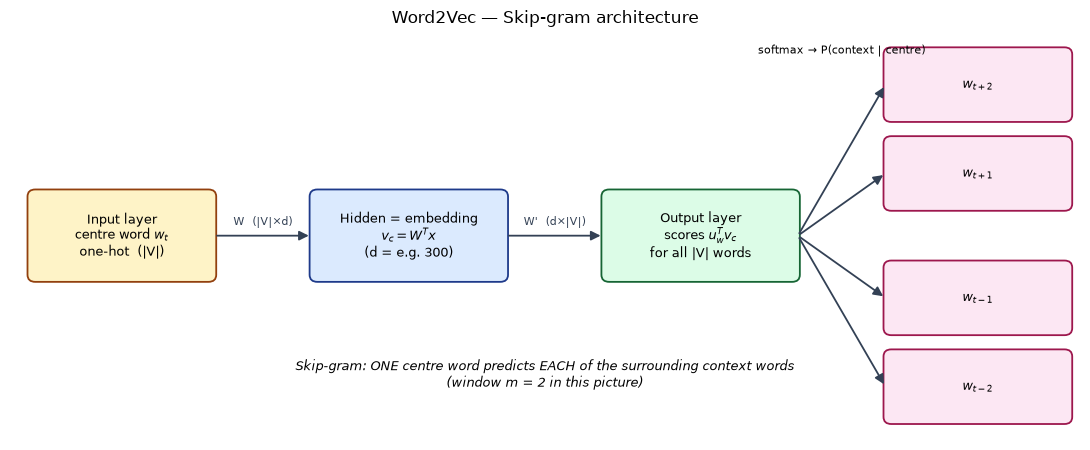

In [3]:
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.set_xlim(0, 11); ax.set_ylim(0, 4.6); ax.axis("off")

box(ax, 0.2, 1.8, 1.9, 1.0, "Input layer\ncentre word $w_t$\none-hot  (|V|)", fc="#fef3c7", ec="#92400e")
box(ax, 3.1, 1.8, 2.0, 1.0, "Hidden = embedding\n$v_c = W^T x$\n(d = e.g. 300)", fc="#dbeafe")
box(ax, 6.1, 1.8, 2.0, 1.0, "Output layer\nscores $u_w^T v_c$\nfor all |V| words", fc="#dcfce7", ec="#166534")
arrow(ax, 2.1, 2.3, 3.1, 2.3, "W  (|V|×d)")
arrow(ax, 5.1, 2.3, 6.1, 2.3, "W'  (d×|V|)")

box(ax, 9.0, 0.2, 1.9, 0.8, "$w_{t-2}$", fc="#fce7f3", ec="#9d174d")
box(ax, 9.0, 1.2, 1.9, 0.8, "$w_{t-1}$", fc="#fce7f3", ec="#9d174d")
box(ax, 9.0, 2.6, 1.9, 0.8, "$w_{t+1}$", fc="#fce7f3", ec="#9d174d")
box(ax, 9.0, 3.6, 1.9, 0.8, "$w_{t+2}$", fc="#fce7f3", ec="#9d174d")
for yy in (0.6, 1.6, 3.0, 4.0):
    arrow(ax, 8.1, 2.3, 9.0, yy)
ax.text(8.55, 4.35, "softmax → P(context | centre)", ha="center", fontsize=8)
ax.text(5.5, 0.6, "Skip-gram: ONE centre word predicts EACH of the surrounding context words\n(window m = 2 in this picture)", ha="center", fontsize=9, style="italic")
ax.set_title("Word2Vec — Skip-gram architecture", fontsize=12)
plt.tight_layout(); plt.show()

### 1(c) Skip-gram **without** vs **with** negative sampling

Let $v_c$ be the vector of the centre word $c$, $u_o$ the output vector of the true context word $o$, and $V$ the vocabulary.

**Without negative sampling (full softmax):**

$$P(o\mid c)=\frac{\exp(u_o^{\top}v_c)}{\sum_{w\in V}\exp(u_w^{\top}v_c)},\qquad J_{\text{softmax}}=-\log P(o\mid c)=-u_o^{\top}v_c+\log\sum_{w\in V}\exp(u_w^{\top}v_c)$$

* It is a **$|V|$-way classification** for every (centre, context) pair.
* The normaliser $\sum_{w\in V}$ touches **all $|V|$ output vectors**, so every update costs $O(|V|\cdot d)$ – very slow for $|V|\approx 10^5$–$10^6$.

**With negative sampling (SGNS):** the big classification is replaced by **$K+1$ small binary (logistic) classifications**: "is $(c,o)$ a *real* pair?" (label 1) and "is $(c,w_k)$ a real pair?" for $K$ random **noise words** $w_k$ (label 0).

$$J_{\text{NS}}=-\log\sigma(u_o^{\top}v_c)\;-\;\sum_{k=1}^{K}\log\sigma(-u_{w_k}^{\top}v_c),\qquad w_k\sim P_n(w)\propto f(w)^{3/4}$$

where $\sigma(x)=1/(1+e^{-x})$ and $f(w)$ is the unigram frequency (the power $3/4$ samples rare words a bit more often).

| | without NS | with NS |
|---|---|---|
| Output | softmax over **all** $V$ | sigmoid on $K+1$ words |
| Cost per pair | $O(\lvert V\rvert d)$ | $O((K+1)\,d)$, $K\approx5$–$20$ |
| Normalisation | exact, over the whole vocabulary | **none** (no partition function) |
| Gradient touches | every output vector | only $u_o$ and the $K$ negatives (+ $v_c$) |
| Objective | exact log-likelihood of context | a simplification of NCE; not the same likelihood, but gives equally good vectors |

### Demo: TF-IDF vs Word2Vec on a tiny corpus (and both Skip-gram variants, from scratch)

The toy corpus is built so that **`cat` and `dog` never appear in the same sentence** but share the **same contexts** (`sat on the ...`, `ate the ...`). A document-based TF-IDF representation cannot see that they are similar; Word2Vec should.

In [4]:
corpus = []
for animal in ["cat", "dog"]:
    for place in ["mat", "rug"]:
        corpus.append(f"the {animal} sat on the {place}")
    corpus.append(f"the {animal} ate the food")
    corpus.append(f"the {animal} ate the fish")
    corpus.append(f"the {animal} ran to the garden")
    corpus.append(f"a {animal} sat on the mat")
tokens = [s.split() for s in corpus]
vocab = sorted({w for s in tokens for w in s})
w2i = {w: i for i, w in enumerate(vocab)}
V = len(vocab)
print(f"{len(corpus)} sentences, |V| = {V}:", vocab)

# ---------- (1) TF-IDF word vectors: each word is described by the documents it appears in ----------
N = len(corpus)
tf = np.array([[s.count(w) for w in vocab] for s in tokens], dtype=float)         # docs x words
dfreq = (tf > 0).sum(axis=0)
tfidf = tf * np.log(N / dfreq)                                                    # docs x words
word_vecs_tfidf = tfidf.T                                                         # words x docs

def cos(a, b):
    na, nb = np.linalg.norm(a), np.linalg.norm(b)
    return float(a @ b / (na * nb)) if na > 0 and nb > 0 else 0.0

print("\nTF-IDF  cos(cat, dog) =", round(cos(word_vecs_tfidf[w2i['cat']], word_vecs_tfidf[w2i['dog']]), 3),
      "  (they never share a sentence)")

12 sentences, |V| = 14: ['a', 'ate', 'cat', 'dog', 'fish', 'food', 'garden', 'mat', 'on', 'ran', 'rug', 'sat', 'the', 'to']

TF-IDF  cos(cat, dog) = 0.0   (they never share a sentence)


training pairs: 200


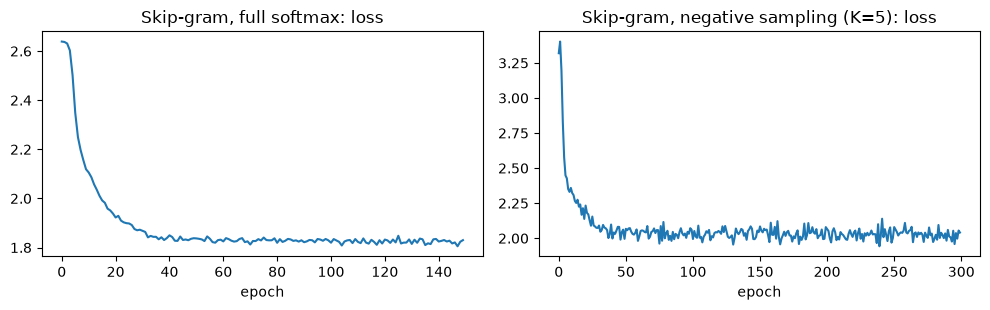

In [5]:
# ---------- (2) Skip-gram from scratch: full softmax  vs  negative sampling ----------
WINDOW, DIM = 2, 12
pairs = []                                    # (centre index, context index)
for s in tokens:
    for i, w in enumerate(s):
        for j in range(max(0, i - WINDOW), min(len(s), i + WINDOW + 1)):
            if j != i:
                pairs.append((w2i[w], w2i[s[j]]))
pairs = np.array(pairs)
print("training pairs:", len(pairs))

freq = np.array([sum(s.count(w) for s in tokens) for w in vocab], dtype=float)
noise_p = freq ** 0.75
noise_p /= noise_p.sum()                      # P_n(w) ∝ f(w)^(3/4)

def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))

def train_skipgram(mode, epochs=150, lr=0.05, K=5, seed=0):
    rs = np.random.RandomState(seed)
    W_in = (rs.rand(V, DIM) - 0.5) / DIM      # v_c  (centre vectors)
    W_out = np.zeros((V, DIM))                # u_w  (context vectors)
    losses = []
    for ep in range(epochs):
        total = 0.0
        for c, o in pairs[rs.permutation(len(pairs))]:
            v = W_in[c]
            if mode == "softmax":                              # full softmax over all |V| words
                scores = W_out @ v
                p = np.exp(scores - scores.max()); p /= p.sum()
                total += -np.log(p[o] + 1e-12)
                dscore = p.copy(); dscore[o] -= 1.0            # dJ/dscores
                dv = W_out.T @ dscore
                W_out -= lr * np.outer(dscore, v)
                W_in[c] -= lr * dv
            else:                                              # negative sampling
                negs = rs.choice(V, size=K, p=noise_p)
                negs = negs[(negs != o) & (negs != c)]
                s_pos = sigmoid(W_out[o] @ v)
                s_neg = sigmoid(W_out[negs] @ v)
                total += -np.log(s_pos + 1e-12) - np.log(1 - s_neg + 1e-12).sum()
                dv = (s_pos - 1) * W_out[o] + (s_neg[:, None] * W_out[negs]).sum(axis=0)
                W_out[o] -= lr * (s_pos - 1) * v
                np.add.at(W_out, negs, -lr * s_neg[:, None] * v[None, :])
                W_in[c] -= lr * dv
        losses.append(total / len(pairs))
    return W_in, losses

emb_soft, loss_soft = train_skipgram("softmax")
emb_ns, loss_ns = train_skipgram("ns", epochs=300)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(loss_soft); ax[0].set_title("Skip-gram, full softmax: loss"); ax[0].set_xlabel("epoch")
ax[1].plot(loss_ns);   ax[1].set_title("Skip-gram, negative sampling (K=5): loss"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

In [6]:
def nearest(emb, word, n=3):
    sims = [(w, cos(emb[w2i[word]], emb[w2i[w]])) for w in vocab if w != word]
    return sorted(sims, key=lambda x: -x[1])[:n]

rows = []
for name, emb in [("TF-IDF (term-document)", word_vecs_tfidf), ("Skip-gram, full softmax", emb_soft), ("Skip-gram, neg. sampling", emb_ns)]:
    rows.append({"Representation": name,
                 "cos(cat, dog)": cos(emb[w2i["cat"]], emb[w2i["dog"]]),
                 "cos(mat, rug)": cos(emb[w2i["mat"]], emb[w2i["rug"]]),
                 "cos(cat, garden)": cos(emb[w2i["cat"]], emb[w2i["garden"]])})
display(pd.DataFrame(rows).set_index("Representation").round(3))

print("Nearest neighbours of 'cat':")
print("  TF-IDF           :", [(w, round(s, 2)) for w, s in nearest(word_vecs_tfidf, "cat")])
print("  softmax Skip-gram:", [(w, round(s, 2)) for w, s in nearest(emb_soft, "cat")])
print("  NS Skip-gram     :", [(w, round(s, 2)) for w, s in nearest(emb_ns, "cat")])

print("\nCost of ONE (centre, context) update:")
print(f"  full softmax : scores for all |V| = {V} words  ->  O(|V|·d) = {V*DIM} multiply-adds (grows with vocabulary)")
print(f"  neg. sampling: 1 positive + K = 5 negatives    ->  O((K+1)·d) = {6*DIM} multiply-adds (independent of |V|)")

,"cos(cat, dog)","cos(mat, rug)","cos(cat, garden)"
Representation,,,
TF-IDF (term-document),0.000,0.000,0.289
"Skip-gram, full softmax",0.999,0.998,0.414
"Skip-gram, neg. sampling",0.988,0.999,0.556


Nearest neighbours of 'cat':
  TF-IDF           : [('on', 0.5), ('sat', 0.5), ('ate', 0.41)]
  softmax Skip-gram: [('dog', 1.0), ('rug', 0.71), ('mat', 0.69)]
  NS Skip-gram     : [('dog', 0.99), ('food', 0.59), ('fish', 0.58)]

Cost of ONE (centre, context) update:
  full softmax : scores for all |V| = 14 words  ->  O(|V|·d) = 168 multiply-adds (grows with vocabulary)
  neg. sampling: 1 positive + K = 5 negatives    ->  O((K+1)·d) = 72 multiply-adds (independent of |V|)


**Reading the result.** TF-IDF gives `cos(cat, dog) = 0` because no document contains both words — it only knows *which documents* a word is in. Both Skip-gram variants place `cat` and `dog` close together (and `mat`/`rug`) because they are predicted from the same neighbours. The toy corpus is tiny, so exact numbers vary with the random seed, but the *pattern* (TF-IDF = 0, Word2Vec clearly > 0) is the point. Negative sampling reaches a similar geometry while its per-update cost does **not** depend on $|V|$.

## Question 2 — Beam search decoding with beam width k = 2  `[CO1] [4+1+1=6]`

**Problem.** A neural language model over $V=\{\text{cat, sat, mat, </s>}\}$ gives the conditional probabilities $P(w_t\mid w_1,\dots,w_{t-1})$ listed in the question. Trace beam search with $k=2$ over $t=1,2,3$.

### Idea of beam search

Greedy decoding keeps only the single best word at every step and can miss a better sentence. **Beam search keeps the $k$ best *partial sentences* (hypotheses)** at every step:

1. Start with one hypothesis: the empty prefix after `<s>`, score $1$.
2. **Expand** each kept hypothesis with every possible next word; the new score is the **cumulative probability**
$$P(w_1\dots w_t)=P(w_1\dots w_{t-1})\cdot P(w_t\mid w_1\dots w_{t-1})$$
3. Out of **all** expanded hypotheses (from all beams together) **keep only the top $k$**; discard the rest (**pruning**).
4. Repeat until the last step; the best surviving hypothesis is the output.

(In practice log-probabilities $\sum\log P$ are added instead of multiplying probabilities, to avoid underflow; the ranking is identical.)

### Hand trace

**t = 1** (expand `<s>`): cat = 0.5, sat = 0.3, mat = 0.2 → keep top 2: **cat (0.5)**, **sat (0.3)**; `mat (0.2)` is pruned.

**t = 2:**

| from | expansion | cumulative probability |
|---|---|---|
| cat (0.5) | cat **sat** | 0.5 × 0.6 = **0.30** ✔ |
| cat (0.5) | cat mat | 0.5 × 0.3 = 0.15 |
| cat (0.5) | cat </s> | 0.5 × 0.1 = 0.05 |
| sat (0.3) | sat cat | 0.3 × 0.2 = 0.06 |
| sat (0.3) | sat **mat** | 0.3 × 0.7 = **0.21** ✔ |
| sat (0.3) | sat </s> | 0.3 × 0.1 = 0.03 |

Top 2 kept: **cat sat (0.30)**, **sat mat (0.21)**.

**t = 3:**

| from | expansion | cumulative probability |
|---|---|---|
| cat sat (0.30) | cat sat **mat** | 0.30 × 0.8 = **0.24** ✔ |
| cat sat (0.30) | cat sat </s> | 0.30 × 0.2 = 0.06 |
| sat mat (0.21) | sat mat cat | 0.21 × 0.1 = 0.021 |
| sat mat (0.21) | sat mat **</s>** | 0.21 × 0.9 = **0.189** ✔ |

Top 2 kept: **cat sat mat (0.24)**, **sat mat </s> (0.189)**.

**Final output: `cat sat mat` with probability 0.24.** (Length-normalised scores $P^{1/3}$ give 0.621 vs 0.574, so the same hypothesis wins. If one insists on a sentence that already *ended* with `</s>`, the best finished one is `sat mat </s>` = 0.189.)

### Why do we ignore $P(\text{cat}\mid\text{mat})$ and $P(\text{sat}\mid\text{mat})$?

Because the hypothesis ending in `mat` was **pruned**. At $t=1$ `mat` (0.2) is not among the top $k=2$, so it is never expanded; those probabilities would only be needed to extend the prefix `mat`. (Likewise `cat mat` (0.15) was pruned at $t=2$.) Beam search only computes next-word distributions for the **surviving** hypotheses – that is exactly what makes it cheaper than exhaustive search.

### Code

In [7]:
EOS = "</s>"

# Conditional probabilities exactly as given in the question, keyed by the prefix (history of words so far)
COND = {
    ():              {"cat": 0.5, "sat": 0.3, "mat": 0.2},                 # t=1, given <s>
    ("cat",):        {"sat": 0.6, "mat": 0.3, EOS: 0.1},                   # t=2
    ("sat",):        {"cat": 0.2, "mat": 0.7, EOS: 0.1},
    ("cat", "sat"):  {"mat": 0.8, EOS: 0.2},                               # t=3
    ("sat", "mat"):  {"cat": 0.1, EOS: 0.9},
}

def next_dist(prefix):
    if prefix not in COND:
        raise KeyError(f"P(. | {' '.join(prefix)}) is not available - this hypothesis should have been pruned")
    return COND[prefix]

def beam_search(k, steps=3):
    """Returns (final beam, list of per-step tables). Each hypothesis = (tuple_of_words, cumulative_probability)."""
    beam = [((), 1.0)]
    tables = []
    for t in range(1, steps + 1):
        candidates = []
        for prefix, p in beam:
            if prefix and prefix[-1] == EOS:                  # finished hypothesis: carry over unchanged
                candidates.append((prefix, p, f"{p:.4g} (finished)"))
                continue
            for w, pw in next_dist(prefix).items():
                candidates.append((prefix + (w,), p * pw, f"{p:.4g} x {pw}"))
        candidates.sort(key=lambda x: -x[1])
        kept = candidates[:k]
        tables.append(pd.DataFrame({
            "hypothesis": [" ".join(c[0]) for c in candidates],
            "computation": [c[2] for c in candidates],
            "cumulative P": [c[1] for c in candidates],
            "kept (top-%d)" % k: ["YES" if i < k else "pruned" for i in range(len(candidates))],
        }))
        beam = [(c[0], c[1]) for c in kept]
    return beam, tables

beam, tables = beam_search(k=2, steps=3)
for t, tab in enumerate(tables, start=1):
    print(f"\n=== t = {t} ===")
    display(tab.round(4))

best_seq, best_p = beam[0]
print("\nFinal beam:", [(" ".join(s), round(p, 4)) for s, p in beam])
print("FINAL OUTPUT:", " ".join(best_seq), f"  (P = {best_p:.4f})")


=== t = 1 ===


,hypothesis,computation,cumulative P,kept (top-2)
0,cat,1 x 0.5,0.5,YES
1,sat,1 x 0.3,0.3,YES
2,mat,1 x 0.2,0.2,pruned



=== t = 2 ===


,hypothesis,computation,cumulative P,kept (top-2)
0,cat sat,0.5 x 0.6,0.30,YES
1,sat mat,0.3 x 0.7,0.21,YES
2,cat mat,0.5 x 0.3,0.15,pruned
3,sat cat,0.3 x 0.2,0.06,pruned
4,cat </s>,0.5 x 0.1,0.05,pruned
5,sat </s>,0.3 x 0.1,0.03,pruned



=== t = 3 ===


,hypothesis,computation,cumulative P,kept (top-2)
0,cat sat mat,0.3 x 0.8,0.240,YES
1,sat mat </s>,0.21 x 0.9,0.189,YES
2,cat sat </s>,0.3 x 0.2,0.060,pruned
3,sat mat cat,0.21 x 0.1,0.021,pruned



Final beam: [('cat sat mat', 0.24), ('sat mat </s>', 0.189)]
FINAL OUTPUT: cat sat mat   (P = 0.2400)


### Check 1 — compare with greedy decoding and exhaustive search

Greedy keeps only one hypothesis ($k=1$); exhaustive search scores **every** sequence the table allows. Beam search with $k=2$ should find the best 3-word sequence here.

In [8]:
greedy, _ = beam_search(k=1, steps=3)
print("Greedy (k=1)      :", " ".join(greedy[0][0]), round(greedy[0][1], 4))

# exhaustive search over every path the probability table defines
def all_paths(prefix=(), p=1.0, depth=3):
    if depth == 0 or (prefix and prefix[-1] == EOS):
        yield prefix, p
        return
    if prefix not in COND:                     # table gives no continuation (e.g. 'mat', 'cat mat') -> stop
        return
    for w, pw in COND[prefix].items():
        yield from all_paths(prefix + (w,), p * pw, depth - 1)

paths = sorted(all_paths(), key=lambda x: -x[1])
print("Exhaustive search, best 3 paths:")
for s, p in paths[:3]:
    print("   ", " ".join(s), round(p, 4))
print("Beam (k=2) found the best path:", " ".join(beam[0][0]) == " ".join(paths[0][0]))

Greedy (k=1)      : cat sat mat 0.24
Exhaustive search, best 3 paths:
    cat sat mat 0.24
    sat mat </s> 0.189
    cat sat </s> 0.06
Beam (k=2) found the best path: True


### Check 2 — "why ignore P(cat|mat), P(sat|mat)?" demonstrated

With a **wider beam ($k=3$)** the hypothesis `mat` *would* survive step 1 and its next-word distribution would be needed – but the question does not provide it, and the code raises exactly that error. With $k=2$ it is never requested.

In [9]:
try:
    beam_search(k=3, steps=3)
except KeyError as e:
    print("k = 3 needs a distribution the question does not give ->", e)
print("k = 2 never asks for P(. | mat): OK (see the t=1 table above, 'mat' is pruned)")

k = 3 needs a distribution the question does not give -> 'P(. | mat) is not available - this hypothesis should have been pruned'
k = 2 never asks for P(. | mat): OK (see the t=1 table above, 'mat' is pruned)


## Question 3 — Learning a sentence representation with an RNN (or LSTM/GRU)  `[CO3] [2+2+2=6]`

### (a) How do we get a sentence representation from an RNN?

An RNN reads the sentence **one word at a time** and keeps a hidden state that summarises everything read so far:

$$h_t=f(W_{xh}\,x_t+W_{hh}\,h_{t-1}+b),\qquad x_t=\text{embedding of word }t,\quad h_0=\mathbf 0$$

The **sentence vector** $s$ is taken from the hidden states, e.g.

* the **last hidden state** $s=h_T$ (it has "seen" the whole sentence), or
* for a **bidirectional** RNN: $s=[\overrightarrow{h}_T;\overleftarrow{h}_1]$ (reads left→right and right→left), or
* a **pooling** over time: mean / max of $h_1,\dots,h_T$ (or attention-weighted sum).

**LSTM / GRU** replace $f$ by gated updates, which let information (and gradients) survive over long sentences:
$$\text{LSTM: } c_t=f_t\odot c_{t-1}+i_t\odot\tilde c_t,\quad h_t=o_t\odot\tanh(c_t)$$

### (b) What is the training data?

The RNN is trained **through a task**; the sentence vector is a by-product. Typical choices:

| Setting | Training data | What the vector is trained to do |
|---|---|---|
| **Supervised** | sentences **with labels** (sentiment, topic, language, entailment pairs …) | make $s$ predict the label |
| **Unsupervised: sequence auto-encoder** | **raw sentences only** (the sentence is its own target) | $s$ must contain enough information for a decoder RNN to **re-generate** the sentence |
| **Unsupervised: language model / Skip-thought** | raw text, ordered sentences | $s$ predicts the next words / the neighbouring sentences |

### (c) Objective function

* **Supervised (classification):** cross-entropy over the labelled sentences
$$\mathcal L=-\sum_{(x,y)}\log P(y\mid x),\qquad P(y\mid x)=\text{softmax}(W_y\,s+b_y)$$
* **Auto-encoder:** negative log-likelihood of re-generating every word
$$\mathcal L=-\sum_{t=1}^{T}\log P(w_t\mid w_{<t},\,s)$$

### (d) How is back-propagation done? — Back-Propagation Through Time (BPTT)

The RNN is **unrolled** over the $T$ time steps into a deep feed-forward network whose layers **share the same weights**. The loss gradient flows backwards through time; the gradients of the shared weights from all time steps are **summed**. For the vanilla (tanh) RNN with the loss computed on $h_T$:

$$\delta_T=\frac{\partial\mathcal L}{\partial h_T}\odot(1-h_T^2),\qquad \delta_t=\big(W_{hh}^{\top}\delta_{t+1}\big)\odot(1-h_t^2)$$
$$\frac{\partial\mathcal L}{\partial W_{hh}}=\sum_{t=1}^{T}\delta_t\,h_{t-1}^{\top},\quad \frac{\partial\mathcal L}{\partial W_{xh}}=\sum_{t=1}^{T}\delta_t\,x_t^{\top},\quad \frac{\partial\mathcal L}{\partial b}=\sum_{t=1}^{T}\delta_t$$

The repeated product of $W_{hh}^{\top}$ makes gradients **vanish or explode** for long sentences → use **gradient clipping** and **LSTM/GRU** gates. The embeddings receive the gradient $W_{xh}^{\top}\delta_t$ and are updated as well.

### Architecture (supervised version; swap the head for a decoder to get an auto-encoder)

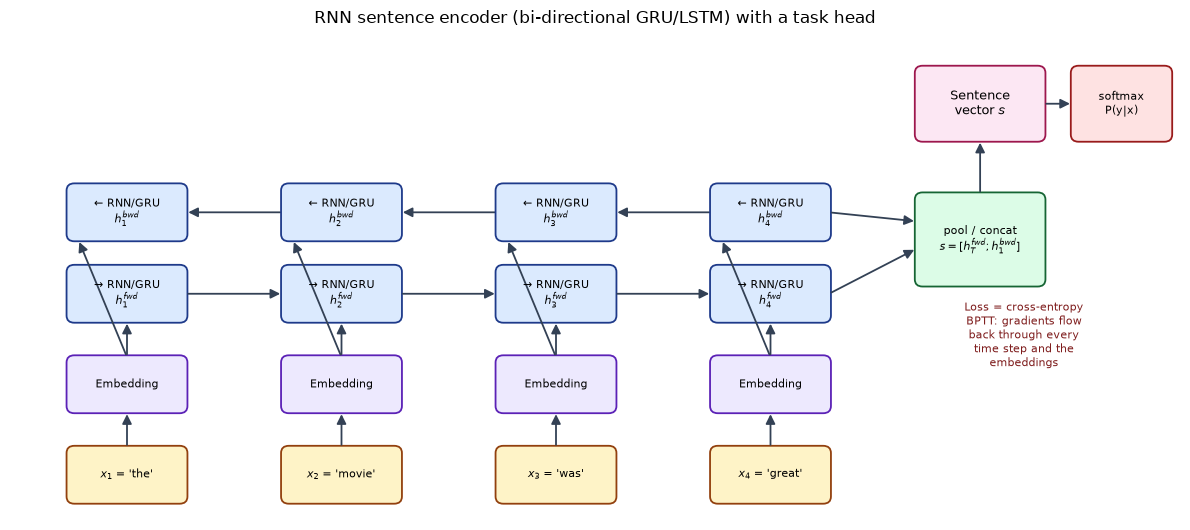

In [10]:
fig, ax = plt.subplots(figsize=(12, 5.4))
ax.set_xlim(0, 12); ax.set_ylim(0, 5.4); ax.axis("off")
words = ["the", "movie", "was", "great"]
xs = [1.2, 3.4, 5.6, 7.8]
for i, (w, x) in enumerate(zip(words, xs)):
    box(ax, x - 0.6, 0.2, 1.2, 0.6, f"$x_{i+1}$ = '{w}'", fc="#fef3c7", ec="#92400e", fs=8)
    box(ax, x - 0.6, 1.2, 1.2, 0.6, "Embedding", fc="#ede9fe", ec="#5b21b6", fs=8)
    box(ax, x - 0.6, 2.2, 1.2, 0.6, f"→ RNN/GRU\n$h^{{fwd}}_{i+1}$", fc="#dbeafe", fs=8)
    box(ax, x - 0.6, 3.1, 1.2, 0.6, f"← RNN/GRU\n$h^{{bwd}}_{i+1}$", fc="#dbeafe", fs=8)
    arrow(ax, x, 0.8, x, 1.2); arrow(ax, x, 1.8, x, 2.2)
    arrow(ax, x, 1.8, x - 0.5, 3.1)
    if i < 3:
        arrow(ax, x + 0.6, 2.5, xs[i + 1] - 0.6, 2.5)
        arrow(ax, xs[i + 1] - 0.6, 3.4, x + 0.6, 3.4)
box(ax, 9.3, 2.6, 1.3, 1.0, "pool / concat\n$s=[h^{fwd}_T ; h^{bwd}_1]$", fc="#dcfce7", ec="#166534", fs=8)
arrow(ax, 8.4, 2.5, 9.3, 3.0); arrow(ax, 8.4, 3.4, 9.3, 3.3)
box(ax, 9.3, 4.2, 1.3, 0.8, "Sentence\nvector $s$", fc="#fce7f3", ec="#9d174d", fs=9)
arrow(ax, 9.95, 3.6, 9.95, 4.2)
box(ax, 10.9, 4.2, 1.0, 0.8, "softmax\nP(y|x)", fc="#fee2e2", ec="#991b1b", fs=8)
arrow(ax, 10.6, 4.6, 10.9, 4.6)
ax.text(10.4, 1.7, "Loss = cross-entropy\nBPTT: gradients flow\nback through every\ntime step and the\nembeddings", fontsize=8, ha="center", color="#7f1d1d")
ax.set_title("RNN sentence encoder (bi-directional GRU/LSTM) with a task head", fontsize=12)
plt.tight_layout(); plt.show()

### Code 1 — BPTT written by hand and verified against PyTorch autograd

A tiny vanilla RNN (3-d inputs, 4-d hidden state, 5 time steps) with a softmax output on the last hidden state. The gradient formulas above are implemented in NumPy and compared with PyTorch's automatic differentiation: they must agree to ~1e-8.

In [11]:
rs = np.random.RandomState(0)
d_in, d_h, T, n_cls = 3, 4, 5, 2
X = rs.randn(T, d_in)
W_xh, W_hh, b = rs.randn(d_h, d_in) * 0.5, rs.randn(d_h, d_h) * 0.5, np.zeros(d_h)
W_y, y_true = rs.randn(n_cls, d_h) * 0.5, 1

# ---- forward ----
hs = [np.zeros(d_h)]                                   # h_0 = 0
for t in range(T):
    hs.append(np.tanh(W_xh @ X[t] + W_hh @ hs[-1] + b))
logits = W_y @ hs[-1]
probs = np.exp(logits - logits.max()); probs /= probs.sum()
loss = -np.log(probs[y_true])
print(f"forward: loss = {loss:.6f}")

# ---- backward (BPTT) ----
dlogits = probs.copy(); dlogits[y_true] -= 1.0
dW_y = np.outer(dlogits, hs[-1])
dh = W_y.T @ dlogits                                   # dL/dh_T
dW_xh, dW_hh, db = np.zeros_like(W_xh), np.zeros_like(W_hh), np.zeros_like(b)
for t in range(T, 0, -1):                              # t = T ... 1
    dz = dh * (1.0 - hs[t] ** 2)                       # delta_t
    dW_xh += np.outer(dz, X[t - 1])
    dW_hh += np.outer(dz, hs[t - 1])
    db += dz
    dh = W_hh.T @ dz                                   # pass gradient to h_{t-1}

# ---- check with autograd ----
try:
    import torch
    tX = torch.tensor(X); tp = [torch.tensor(a, requires_grad=True) for a in (W_xh, W_hh, b, W_y)]
    h = torch.zeros(d_h, dtype=torch.float64)
    for t in range(T):
        h = torch.tanh(tp[0] @ tX[t] + tp[1] @ h + tp[2])
    tloss = torch.nn.functional.cross_entropy((tp[3] @ h).unsqueeze(0), torch.tensor([y_true]))
    tloss.backward()
    for name, mine, ref in zip(["W_xh", "W_hh", "b", "W_y"], [dW_xh, dW_hh, db, dW_y], [p.grad.numpy() for p in tp]):
        print(f"  {name:<5} max |manual - autograd| = {np.abs(mine - ref).max():.2e}")
except ImportError:
    # fallback: numerical gradient check for one entry
    eps = 1e-6
    def loss_fn(Whh):
        h = np.zeros(d_h)
        for t in range(T):
            h = np.tanh(W_xh @ X[t] + Whh @ h + b)
        lg = W_y @ h; p = np.exp(lg - lg.max()); p /= p.sum()
        return -np.log(p[y_true])
    Wp = W_hh.copy(); Wp[0, 0] += eps
    print("numeric dL/dW_hh[0,0] =", (loss_fn(Wp) - loss_fn(W_hh)) / eps, " manual =", dW_hh[0, 0])

forward: loss = 0.507049
  W_xh  max |manual - autograd| = 5.55e-17
  W_hh  max |manual - autograd| = 8.33e-17
  b     max |manual - autograd| = 8.33e-17
  W_y   max |manual - autograd| = 1.11e-16


### Code 2 — a bi-directional GRU sentence encoder trained on labelled sentences (PyTorch)

Toy supervised task: classify short sentences as **positive / negative**. After training, the vector $s$ of each sentence is read out and we check that sentences with the same sentiment are close to each other.

final loss 0.0000, training accuracy 100.00%


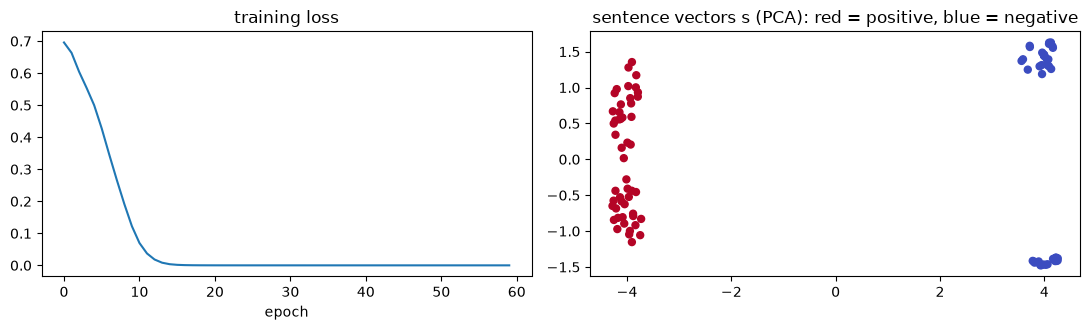

pos: the movie was great | pos: the movie was wonderful | neg: the movie was terrible
cos(pos1,pos2) = 0.934   cos(pos1,neg) = -0.751


In [12]:
try:
    import torch, torch.nn as nn
    HAS_TORCH = True
except ImportError:
    HAS_TORCH = False
    print("PyTorch not installed - skipping this demo (pip install torch).")

if HAS_TORCH:
    torch.manual_seed(0)
    pos_words = ["great", "wonderful", "excellent", "amazing", "good"]
    neg_words = ["terrible", "awful", "boring", "bad", "poor"]
    subjects = ["movie", "food", "book", "service", "game"]
    data = []
    for s in subjects:
        for w in pos_words: data += [(f"the {s} was {w}", 1), (f"i found the {s} {w}", 1)]
        for w in neg_words: data += [(f"the {s} was {w}", 0), (f"i found the {s} {w}", 0)]
    sent_vocab = {"<pad>": 0}
    for text, _ in data:
        for w in text.split(): sent_vocab.setdefault(w, len(sent_vocab))

    def encode_batch(batch):
        seqs = [torch.tensor([sent_vocab[w] for w in t.split()]) for t, _ in batch]
        lengths = torch.tensor([len(s) for s in seqs])
        padded = nn.utils.rnn.pad_sequence(seqs, batch_first=True)
        return padded, lengths, torch.tensor([y for _, y in batch])

    class SentenceEncoder(nn.Module):
        def __init__(self, vocab_size, emb=16, hid=16):
            super().__init__()
            self.emb = nn.Embedding(vocab_size, emb, padding_idx=0)
            self.rnn = nn.GRU(emb, hid, batch_first=True, bidirectional=True)
            self.head = nn.Linear(2 * hid, 2)
        def sentence_vector(self, x, lengths):
            packed = nn.utils.rnn.pack_padded_sequence(self.emb(x), lengths, batch_first=True, enforce_sorted=False)
            _, h_n = self.rnn(packed)                       # h_n: (2, B, hid) = last forward, last backward
            return torch.cat([h_n[0], h_n[1]], dim=1)        # s = [h_fwd(T) ; h_bwd(1)]
        def forward(self, x, lengths):
            return self.head(self.sentence_vector(x, lengths))

    model = SentenceEncoder(len(sent_vocab))
    opt = torch.optim.Adam(model.parameters(), lr=0.02)
    xb, lb, yb = encode_batch(data)
    history = []
    for epoch in range(60):
        opt.zero_grad()
        loss = nn.functional.cross_entropy(model(xb, lb), yb)
        loss.backward()                                     # <- BPTT through the unrolled GRU
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        history.append(loss.item())
    acc = (model(xb, lb).argmax(1) == yb).float().mean().item()
    print(f"final loss {history[-1]:.4f}, training accuracy {acc:.2%}")

    with torch.no_grad():
        S = model.sentence_vector(xb, lb).numpy()
    # PCA to 2-D for a picture
    Sc = S - S.mean(0)
    _, _, Vt = np.linalg.svd(Sc, full_matrices=False)
    P2 = Sc @ Vt[:2].T
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
    ax[0].plot(history); ax[0].set_title("training loss"); ax[0].set_xlabel("epoch")
    ax[1].scatter(P2[:, 0], P2[:, 1], c=yb.numpy(), cmap="coolwarm", s=25)
    ax[1].set_title("sentence vectors s (PCA): red = positive, blue = negative")
    plt.tight_layout(); plt.show()

    def sent_cos(a, b):
        return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))
    i_pos1, i_pos2, i_neg = 0, 2, 10
    print("pos:", data[i_pos1][0], "| pos:", data[i_pos2][0], "| neg:", data[i_neg][0])
    print("cos(pos1,pos2) =", round(sent_cos(S[i_pos1], S[i_pos2]), 3), "  cos(pos1,neg) =", round(sent_cos(S[i_pos1], S[i_neg]), 3))

**Summary for the answer.** Encoder = (Bi)RNN/LSTM/GRU over word embeddings → sentence vector $s$ (final / pooled hidden state). Data = labelled sentences (supervised) or raw sentences (auto-encoder / LM). Objective = cross-entropy (or word-level NLL for a decoder). Learning = **BPTT**: unroll over time, sum the gradients of the shared weights, clip the gradient norm, update with SGD/Adam; gates in LSTM/GRU keep the gradient from vanishing.

## Question 4 — Byte-Pair Encoding (2 merges)  `[CO2] [2+2+2=6]`

**Corpus**

```
low lower low lower lowest
low lowest low lowest
low new
newest widest widest
new widest
```

### How BPE works

1. Split every word into **characters** and append an **end-of-word marker `</w>`** (so that the model knows where a word ends, e.g. `est</w>` at a word end is different from `est` inside a word).
2. **Count every pair of adjacent symbols**, weighted by the word frequency.
3. **Merge the most frequent pair** into one new symbol and record it as a **merge rule**.
4. Repeat for the wanted number of merges (here 2). The **vocabulary** = all single characters (incl. `</w>`) + the merged symbols.

### Step 0 — word frequencies

| word | low | lower | lowest | new | newest | widest |
|---|---|---|---|---|---|---|
| count | 5 | 2 | 3 | 2 | 1 | 3 |

(low: 2+2+1 = 5, lower: 2, lowest: 1+2 = 3, new: 1+1 = 2, newest: 1, widest: 2+1 = 3)

### Steps 1 and 2

The most frequent pairs are computed in the code below. In short: `(l,o)` and `(o,w)` both occur **10** times (low 5 + lower 2 + lowest 3). Ties are broken by the **first pair encountered** → merge 1 = **`l o → lo`**; then `(lo,w)` has 10 → merge 2 = **`lo w → low`**. (Breaking the first tie the other way, `o w → ow` then `l ow → low`, gives the **same** vocabulary except for the name of the intermediate symbol, and identical segmentations after 2 merges.)

### Code — BPE learning with a full trace

In [13]:
from collections import Counter

corpus_text = """low lower low lower lowest
low lowest low lowest
low new
newest widest widest
new widest"""

word_freq = Counter(corpus_text.split())
print("Word frequencies:", dict(word_freq))

# word (as a tuple of symbols, with </w>) -> frequency
def init_vocab(word_freq):
    return {tuple(w) + ("</w>",): f for w, f in word_freq.items()}

def pair_counts(vocab):
    counts = {}                                 # insertion order = order of first occurrence (used for tie-breaking)
    for symbols, f in vocab.items():
        for a, b in zip(symbols, symbols[1:]):
            counts[(a, b)] = counts.get((a, b), 0) + f
    return counts

def merge_pair(vocab, pair):
    new_vocab = {}
    for symbols, f in vocab.items():
        out, i = [], 0
        while i < len(symbols):
            if i < len(symbols) - 1 and (symbols[i], symbols[i + 1]) == pair:
                out.append(symbols[i] + symbols[i + 1]); i += 2
            else:
                out.append(symbols[i]); i += 1
        new_vocab[tuple(out)] = new_vocab.get(tuple(out), 0) + f
    return new_vocab

def learn_bpe(word_freq, num_merges, verbose=True):
    vocab = init_vocab(word_freq)
    merges = []
    if verbose:
        print("Initial segmentation:")
        for s, f in vocab.items():
            print(f"   {' '.join(s):<28} x{f}")
    for step in range(1, num_merges + 1):
        counts = pair_counts(vocab)
        best = max(counts, key=counts.get)      # first maximum wins ties
        if verbose:
            top = sorted(counts.items(), key=lambda kv: -kv[1])[:6]
            print(f"\n--- merge {step}: top pair counts ---")
            print("   " + ", ".join(f"{a}+{b}:{c}" for (a, b), c in top))
            ties = [p for p, c in counts.items() if c == counts[best]]
            print(f"   chosen: {best}  (count {counts[best]}; tied pairs: {ties})")
        vocab = merge_pair(vocab, best)
        merges.append(best)
        if verbose:
            for s, f in vocab.items():
                print(f"   {' '.join(s):<28} x{f}")
    return vocab, merges

final_vocab, merges = learn_bpe(word_freq, num_merges=2)
print("\nMERGE RULES (in order):")
for i, m in enumerate(merges, 1):
    print(f"   {i}. {m[0]} + {m[1]}  ->  {m[0] + m[1]}")

Word frequencies: {'low': 5, 'lower': 2, 'lowest': 3, 'new': 2, 'newest': 1, 'widest': 3}
Initial segmentation:
   l o w </w>                   x5
   l o w e r </w>               x2
   l o w e s t </w>             x3
   n e w </w>                   x2
   n e w e s t </w>             x1
   w i d e s t </w>             x3

--- merge 1: top pair counts ---
   l+o:10, o+w:10, w+</w>:7, e+s:7, s+t:7, t+</w>:7
   chosen: ('l', 'o')  (count 10; tied pairs: [('l', 'o'), ('o', 'w')])
   lo w </w>                    x5
   lo w e r </w>                x2
   lo w e s t </w>              x3
   n e w </w>                   x2
   n e w e s t </w>             x1
   w i d e s t </w>             x3

--- merge 2: top pair counts ---
   lo+w:10, w+</w>:7, e+s:7, s+t:7, t+</w>:7, w+e:6
   chosen: ('lo', 'w')  (count 10; tied pairs: [('lo', 'w')])
   low </w>                     x5
   low e r </w>                 x2
   low e s t </w>               x3
   n e w </w>                   x2
   n e w e s t </w>   

In [14]:
base_symbols = sorted({s for symbols in init_vocab(word_freq) for s in symbols})
merged_symbols = [a + b for a, b in merges]
final_symbols = base_symbols + merged_symbols
print("FINAL VOCABULARY after 2 merges  (size = %d):" % len(final_symbols))
print("   characters :", base_symbols)
print("   merged     :", merged_symbols)

print("\nSegmentation of the training words:")
seg = pd.DataFrame([{"word": "".join(s).replace("</w>", ""), "count": f, "BPE tokens": " ".join(s)}
                    for s, f in final_vocab.items()])
display(seg)

FINAL VOCABULARY after 2 merges  (size = 13):
   characters : ['</w>', 'd', 'e', 'i', 'l', 'n', 'o', 'r', 's', 't', 'w']
   merged     : ['lo', 'low']

Segmentation of the training words:


,word,count,BPE tokens
0,low,5,low </w>
1,lower,2,low e r </w>
2,lowest,3,low e s t </w>
3,new,2,n e w </w>
4,newest,1,n e w e s t </w>
5,widest,3,w i d e s t </w>


**Result.** Merge rules: **(1) `l o → lo`**, **(2) `lo w → low`**. Vocabulary = the 11 base symbols `d e i l n o r s t w </w>` + `lo`, `low` = **13 symbols**. (`l` and `o` no longer appear on their own in the segmented corpus, but they stay in the vocabulary because they are needed to spell unseen words.)

### How does BPE handle out-of-vocabulary words?

BPE never needs an "unknown word": at test time a new word is split into characters + `</w>` and the **learned merge rules are applied in the same order as in training**. A word that was never seen is therefore broken into the **longest known sub-word pieces**, and in the worst case into single characters. Only a **character that is not in the base vocabulary at all** (e.g. a new script) has to be mapped to `<unk>`.

In [15]:
def bpe_encode(word, merges, base_symbols):
    symbols = [c if c in base_symbols else "<unk>" for c in word] + ["</w>"]
    for a, b in merges:                          # apply the rules in the learned order
        i, out = 0, []
        while i < len(symbols):
            if i < len(symbols) - 1 and symbols[i] == a and symbols[i + 1] == b:
                out.append(a + b); i += 2
            else:
                out.append(symbols[i]); i += 1
        symbols = out
    return symbols

for w in ["low", "lowest", "slow", "lowly", "newer", "widen", "wild", "xyz"]:
    kind = "seen " if w in word_freq else "OOV  "
    print(f"{kind} {w:<8} ->", bpe_encode(w, merges, set(base_symbols)))
print("\nObservations: 'slow' = s + low + </w> (the known piece 'low' is reused); 'newer', 'widen' fall back to characters;")
print("'xyz' contains characters never seen in training, so they become <unk> (the only real failure case).")

seen  low      -> ['low', '</w>']
seen  lowest   -> ['low', 'e', 's', 't', '</w>']
OOV   slow     -> ['s', 'low', '</w>']
OOV   lowly    -> ['low', 'l', '<unk>', '</w>']
OOV   newer    -> ['n', 'e', 'w', 'e', 'r', '</w>']
OOV   widen    -> ['w', 'i', 'd', 'e', 'n', '</w>']
OOV   wild     -> ['w', 'i', 'l', 'd', '</w>']
OOV   xyz      -> ['<unk>', '<unk>', '<unk>', '</w>']

Observations: 'slow' = s + low + </w> (the known piece 'low' is reused); 'newer', 'widen' fall back to characters;
'xyz' contains characters never seen in training, so they become <unk> (the only real failure case).


## Question 5 — TF-IDF of 4 documents, class representation, Doc2Vec  `[CO1+CO3] [2+2+2=6]`

| Document | Text | Class |
|---|---|---|
| D1 | machine learning is useful | Technology |
| D2 | machine learning is powerful | Technology |
| D3 | learning language is useful | Language |
| D4 | language processing is useful | Language |

### Definitions used (no start/end markers, as required)

$$\text{tf}(t,d)=\frac{\text{count of }t\text{ in }d}{\text{number of words in }d},\qquad \text{idf}(t)=\ln\frac{N}{df(t)},\qquad \text{tf-idf}(t,d)=\text{tf}(t,d)\cdot\text{idf}(t)$$

$N=4$ documents, $df(t)$ = number of documents containing $t$. A word that occurs in **every** document ($df=N$) gets idf $=\ln 1=0$ – it carries no information for telling documents apart. (Other textbooks use $\log_{10}$, raw counts as tf, or the smoothed scikit-learn idf $\ln\frac{1+N}{1+df}+1$; only the scale changes – the code shows these variants too.)

### 5(a) Vocabulary and TF-IDF

**Vocabulary (7 words):** `machine, learning, is, useful, powerful, language, processing`.

| word | df | idf = ln(4/df) |
|---|---|---|
| machine | 2 | ln 2 = 0.6931 |
| learning | 3 | ln(4/3) = 0.2877 |
| is | 4 | ln 1 = 0 |
| useful | 3 | ln(4/3) = 0.2877 |
| powerful | 1 | ln 4 = 1.3863 |
| language | 2 | ln 2 = 0.6931 |
| processing | 1 | ln 4 = 1.3863 |

Every document has 4 words, each word appears once → tf = 1/4 = 0.25, so tf-idf = 0.25 × idf (e.g. D1: machine = 0.1733, learning = 0.0719, is = 0, useful = 0.0719).

### Code

In [16]:
docs = {
    "D1": "machine learning is useful",
    "D2": "machine learning is powerful",
    "D3": "learning language is useful",
    "D4": "language processing is useful",
}
labels = {"D1": "Technology", "D2": "Technology", "D3": "Language", "D4": "Language"}

# vocabulary in order of first appearance
vocab = []
for d in docs.values():
    for w in d.split():
        if w not in vocab:
            vocab.append(w)
N = len(docs)
print("Vocabulary (%d words):" % len(vocab), vocab)

df_counts = {w: sum(w in d.split() for d in docs.values()) for w in vocab}

def compute_tfidf(docs, vocab, log=math.log, tf_mode="relative"):
    idf = {w: log(N / df_counts[w]) for w in vocab}
    rows = {}
    for name, text in docs.items():
        toks = text.split()
        row = []
        for w in vocab:
            c = toks.count(w)
            tf = c / len(toks) if tf_mode == "relative" else c
            row.append(tf * idf[w])
        rows[name] = row
    return pd.DataFrame(rows, index=vocab).T, idf

tfidf_df, idf = compute_tfidf(docs, vocab)
display(pd.DataFrame({"df": df_counts, "idf = ln(N/df)": idf}).T.round(4))
print("TF-IDF matrix (rows = documents, tf = count / doc length, idf = ln(N/df)):")
display(tfidf_df.round(4))

# hand-checks against the table in the markdown above
assert abs(tfidf_df.loc["D1", "machine"] - 0.25 * math.log(2)) < 1e-12
assert abs(tfidf_df.loc["D2", "powerful"] - 0.25 * math.log(4)) < 1e-12
assert (tfidf_df["is"] == 0).all()
print("hand-computed values match.")

Vocabulary (7 words): ['machine', 'learning', 'is', 'useful', 'powerful', 'language', 'processing']


,machine,learning,is,useful,powerful,language,processing
df,2.0000,3.0000,4.0,3.0000,1.0000,2.0000,1.0000
idf = ln(N/df),0.6931,0.2877,0.0,0.2877,1.3863,0.6931,1.3863


TF-IDF matrix (rows = documents, tf = count / doc length, idf = ln(N/df)):


,machine,learning,is,useful,powerful,language,processing
D1,0.1733,0.0719,0.0,0.0719,0.0000,0.0000,0.0000
D2,0.1733,0.0719,0.0,0.0000,0.3466,0.0000,0.0000
D3,0.0000,0.0719,0.0,0.0719,0.0000,0.1733,0.0000
D4,0.0000,0.0000,0.0,0.0719,0.0000,0.1733,0.3466


hand-computed values match.


In [17]:
# variants of the formula (only the scale changes)
tfidf_log10, _ = compute_tfidf(docs, vocab, log=math.log10)
tfidf_rawtf, _ = compute_tfidf(docs, vocab, tf_mode="raw")
print("log10 idf, relative tf:"); display(tfidf_log10.round(4))
print("ln idf, RAW count tf (tf = 1):"); display(tfidf_rawtf.round(4))

try:
    from sklearn.feature_extraction.text import TfidfVectorizer
    tv = TfidfVectorizer(smooth_idf=True, norm=None, vocabulary=vocab)
    sk = pd.DataFrame(tv.fit_transform(list(docs.values())).toarray(), index=list(docs), columns=vocab)
    print("scikit-learn convention (idf = ln((1+N)/(1+df)) + 1, raw tf, no normalisation):")
    display(sk.round(4))
except ImportError:
    print("scikit-learn not installed - skipping the cross-check.")

log10 idf, relative tf:


,machine,learning,is,useful,powerful,language,processing
D1,0.0753,0.0312,0.0,0.0312,0.0000,0.0000,0.0000
D2,0.0753,0.0312,0.0,0.0000,0.1505,0.0000,0.0000
D3,0.0000,0.0312,0.0,0.0312,0.0000,0.0753,0.0000
D4,0.0000,0.0000,0.0,0.0312,0.0000,0.0753,0.1505


ln idf, RAW count tf (tf = 1):


,machine,learning,is,useful,powerful,language,processing
D1,0.6931,0.2877,0.0,0.2877,0.0000,0.0000,0.0000
D2,0.6931,0.2877,0.0,0.0000,1.3863,0.0000,0.0000
D3,0.0000,0.2877,0.0,0.2877,0.0000,0.6931,0.0000
D4,0.0000,0.0000,0.0,0.2877,0.0000,0.6931,1.3863


scikit-learn convention (idf = ln((1+N)/(1+df)) + 1, raw tf, no normalisation):


,machine,learning,is,useful,powerful,language,processing
D1,1.5108,1.2231,1.0,1.2231,0.0000,0.0000,0.0000
D2,1.5108,1.2231,1.0,0.0000,1.9163,0.0000,0.0000
D3,0.0000,1.2231,1.0,1.2231,0.0000,1.5108,0.0000
D4,0.0000,0.0000,1.0,1.2231,0.0000,1.5108,1.9163


### 5(b) How do we represent the **classes** through the TF-IDF of the documents?

Each document is a **7-dimensional TF-IDF vector**. A class is then represented by combining the vectors of its documents. Two standard ways:

1. **Class centroid (Rocchio):** $\;\vec c_k=\dfrac{1}{|D_k|}\sum_{d\in D_k}\vec d_{\text{tf-idf}}$ – the *average* TF-IDF vector of all documents of the class. A new document is assigned to the class whose centroid has the **highest cosine similarity** with it.
2. **Class as one big document:** concatenate all documents of a class into a single pseudo-document and compute TF-IDF over the $K$ class-documents (here $N=2$). The weights then say which words are *characteristic of the class*.

Both give each class a vector over the same vocabulary; the largest components are the words that *characterise* the class.

In [18]:
classes = sorted(set(labels.values()))

# --- way 1: centroids of document TF-IDF vectors ---
centroids = pd.DataFrame({c: tfidf_df.loc[[d for d in docs if labels[d] == c]].mean() for c in classes}).T
print("Class centroids (mean TF-IDF of the class's documents):")
display(centroids.round(4))

for c in classes:
    top = centroids.loc[c].sort_values(ascending=False)
    print(f"  most characteristic words of {c:<10}:", [(w, round(v, 3)) for w, v in top.items() if v > 0][:4])

def cosine(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    na, nb = np.linalg.norm(a), np.linalg.norm(b)
    return float(a @ b / (na * nb)) if na > 0 and nb > 0 else 0.0

def tfidf_vector(text):
    toks = text.split()
    return np.array([(toks.count(w) / len(toks)) * idf[w] if len(toks) else 0 for w in vocab])

print("\nClassifying new sentences by cosine similarity to the class centroids:")
for q in ["machine learning is powerful", "language processing is useful", "learning is useful", "powerful machine"]:
    sims = {c: cosine(tfidf_vector(q), centroids.loc[c].values) for c in classes}
    vals = sorted(sims.values())
    verdict = "tie (no class-specific words)" if abs(vals[-1] - vals[-2]) < 1e-9 else max(sims, key=sims.get)
    print(f"  {q!r:<36}", {c: round(s, 3) for c, s in sims.items()}, "->", verdict)

# --- way 2: one pseudo-document per class ---
class_docs = {c: " ".join(docs[d] for d in docs if labels[d] == c) for c in classes}
Nc = len(class_docs)
df_cls = {w: sum(w in t.split() for t in class_docs.values()) for w in vocab}
rows = {}
for c, text in class_docs.items():
    toks = text.split()
    rows[c] = [(toks.count(w) / len(toks)) * math.log(Nc / df_cls[w]) for w in vocab]
print("\nClass-as-document TF-IDF (N = 2 class documents; words in both classes get weight 0):")
display(pd.DataFrame(rows, index=vocab).T.round(4))

Class centroids (mean TF-IDF of the class's documents):


,machine,learning,is,useful,powerful,language,processing
Language,0.0000,0.0360,0.0,0.0719,0.0000,0.1733,0.1733
Technology,0.1733,0.0719,0.0,0.0360,0.1733,0.0000,0.0000


  most characteristic words of Language  : [('language', 0.173), ('processing', 0.173), ('useful', 0.072), ('learning', 0.036)]
  most characteristic words of Technology: [('machine', 0.173), ('powerful', 0.173), ('learning', 0.072), ('useful', 0.036)]

Classifying new sentences by cosine similarity to the class centroids:
  'machine learning is powerful'       {'Language': 0.025, 'Technology': 0.937} -> Technology
  'language processing is useful'      {'Language': 0.937, 'Technology': 0.025} -> Language
  'learning is useful'                 {'Language': 0.296, 'Technology': 0.296} -> tie (no class-specific words)
  'powerful machine'                   {'Language': 0.0, 'Technology': 0.901} -> Technology

Class-as-document TF-IDF (N = 2 class documents; words in both classes get weight 0):


,machine,learning,is,useful,powerful,language,processing
Language,0.0000,0.0,0.0,0.0,0.0000,0.1733,0.0866
Technology,0.1733,0.0,0.0,0.0,0.0866,0.0000,0.0000


### 5(c) How do we learn document representations with **Doc2Vec**?

TF-IDF vectors are sparse, as long as the vocabulary, and ignore word order. **Doc2Vec (Paragraph Vector, Le & Mikolov 2014)** extends Word2Vec so that every document gets its own **dense vector learned by prediction**. A unique **paragraph (document) ID** is added as an extra "word" whose vector $\vec p_d$ is trained together with the word vectors:

* **PV-DM (Distributed Memory)** – extension of **CBOW**: the document vector **and** the context words are combined (average or concatenation) to **predict the next/middle word**. The document vector acts as a memory of what the context alone cannot say.
* **PV-DBOW (Distributed Bag of Words)** – extension of **Skip-gram**: the document vector alone predicts words sampled from the document.

At inference time for a **new** document, the network weights are frozen and only a fresh paragraph vector is trained for a few steps. (Technique name to write in the exam: **Doc2Vec — PV-DM / PV-DBOW**.)

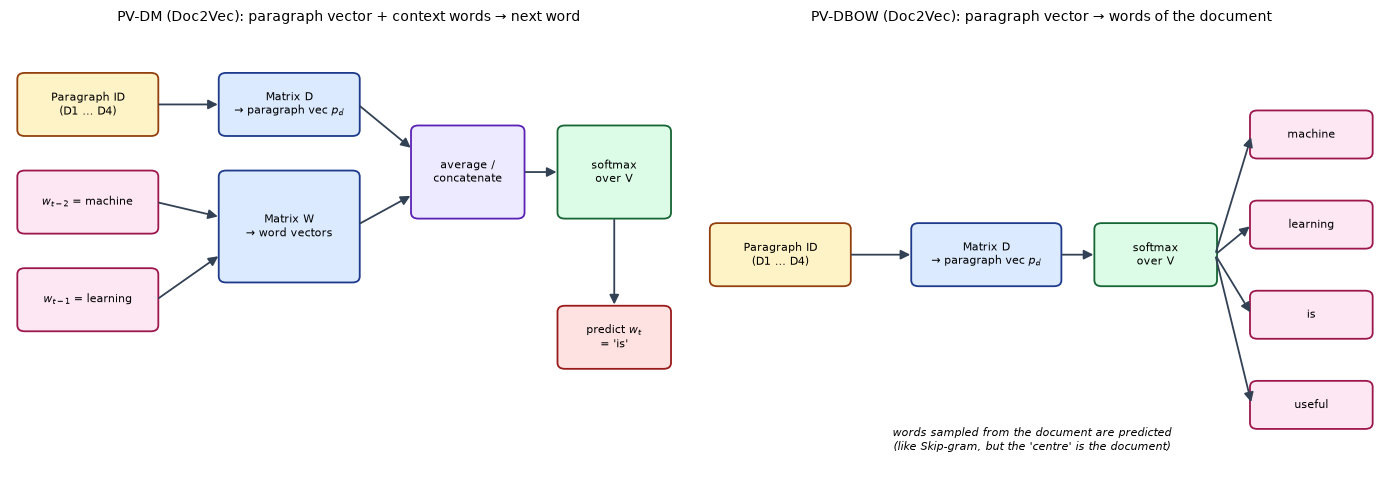

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ---------- PV-DM ----------
ax = axes[0]; ax.set_xlim(0, 7.4); ax.set_ylim(0, 6); ax.axis("off")
box(ax, 0.1, 4.6, 1.5, 0.8, "Paragraph ID\n(D1 … D4)", fc="#fef3c7", ec="#92400e", fs=8)
box(ax, 0.1, 3.3, 1.5, 0.8, "$w_{t-2}$ = machine", fc="#fce7f3", ec="#9d174d", fs=8)
box(ax, 0.1, 2.0, 1.5, 0.8, "$w_{t-1}$ = learning", fc="#fce7f3", ec="#9d174d", fs=8)
box(ax, 2.3, 4.6, 1.5, 0.8, "Matrix D\n→ paragraph vec $p_d$", fc="#dbeafe", fs=8)
box(ax, 2.3, 2.65, 1.5, 1.45, "Matrix W\n→ word vectors", fc="#dbeafe", fs=8)
box(ax, 4.4, 3.5, 1.2, 1.2, "average /\nconcatenate", fc="#ede9fe", ec="#5b21b6", fs=8)
box(ax, 6.0, 3.5, 1.2, 1.2, "softmax\nover V", fc="#dcfce7", ec="#166534", fs=8)
box(ax, 6.0, 1.5, 1.2, 0.8, "predict $w_t$\n= 'is'", fc="#fee2e2", ec="#991b1b", fs=8)
arrow(ax, 1.6, 5.0, 2.3, 5.0); arrow(ax, 1.6, 3.7, 2.3, 3.5); arrow(ax, 1.6, 2.4, 2.3, 3.0)
arrow(ax, 3.8, 5.0, 4.4, 4.4); arrow(ax, 3.8, 3.4, 4.4, 3.8); arrow(ax, 5.6, 4.1, 6.0, 4.1); arrow(ax, 6.6, 3.5, 6.6, 2.3)
ax.set_title("PV-DM (Doc2Vec): paragraph vector + context words → next word", fontsize=10)

# ---------- PV-DBOW ----------
ax = axes[1]; ax.set_xlim(0, 7.4); ax.set_ylim(0, 6); ax.axis("off")
box(ax, 0.1, 2.6, 1.5, 0.8, "Paragraph ID\n(D1 … D4)", fc="#fef3c7", ec="#92400e", fs=8)
box(ax, 2.3, 2.6, 1.6, 0.8, "Matrix D\n→ paragraph vec $p_d$", fc="#dbeafe", fs=8)
box(ax, 4.3, 2.6, 1.3, 0.8, "softmax\nover V", fc="#dcfce7", ec="#166534", fs=8)
for yy, wd in zip((4.6, 3.4, 2.2, 1.0), ("machine", "learning", "is", "useful")):
    box(ax, 6.0, yy - 0.3, 1.3, 0.6, wd, fc="#fce7f3", ec="#9d174d", fs=8)
    arrow(ax, 5.6, 3.0, 6.0, yy)
arrow(ax, 1.6, 3.0, 2.3, 3.0); arrow(ax, 3.9, 3.0, 4.3, 3.0)
ax.text(3.6, 0.4, "words sampled from the document are predicted\n(like Skip-gram, but the 'centre' is the document)", ha="center", fontsize=8, style="italic")
ax.set_title("PV-DBOW (Doc2Vec): paragraph vector → words of the document", fontsize=10)
plt.tight_layout(); plt.show()

Optional demo – train a real Doc2Vec model (gensim) on the 4 documents. With only 4 very short documents the vectors are not meaningful; the point is to see the API and the shape of the result.

In [20]:
try:
    from gensim.models.doc2vec import Doc2Vec, TaggedDocument
    tagged = [TaggedDocument(words=t.split(), tags=[d]) for d, t in docs.items()]
    for name, dm in [("PV-DM", 1), ("PV-DBOW", 0)]:
        model = Doc2Vec(tagged, vector_size=8, window=2, min_count=1, dm=dm, epochs=200, seed=1, workers=1)
        vecs = np.array([model.dv[d] for d in docs])
        print(f"{name}: document-vector matrix shape = {vecs.shape}")
        print("   cos(D1,D2) =", round(cosine(vecs[0], vecs[1]), 3), "  cos(D3,D4) =", round(cosine(vecs[2], vecs[3]), 3),
              "  cos(D1,D4) =", round(cosine(vecs[0], vecs[3]), 3))
    new_vec = model.infer_vector("machine learning is useful".split())
    print("inferred vector for a new text:", np.round(new_vec[:4], 3), "...")
except ImportError:
    print("gensim not installed - run `%pip install gensim` to try the demo.")

PV-DM: document-vector matrix shape = (4, 8)
   cos(D1,D2) = 0.478   cos(D3,D4) = 0.199   cos(D1,D4) = 0.034
PV-DBOW: document-vector matrix shape = (4, 8)
   cos(D1,D2) = 0.565   cos(D3,D4) = 0.146   cos(D1,D4) = 0.071
inferred vector for a new text: [ 0.003  0.028 -0.065  0.017] ...
